In [ ]:
pip install numpy opencv-python scikit-learn scikit-image matplotlib seaborn

In [ ]:
from google.colab import files
files.upload()

import os
os.makedirs("/root/.kaggle", exist_ok=True)
os.rename("kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 600)

!pip install kaggle -q
!kaggle datasets download -d meowmeowmeowmeowmeow/gtsrb-german-traffic-sign -p /content/gtsrb_data --unzip

In [ ]:
!pip install kaggle -q
!kaggle datasets download -d meowmeowmeowmeowmeow/gtsrb-german-traffic-sign -p /content/gtsrb_data --unzip

In [ ]:
import numpy as np
import cv2
from pathlib import Path

IMG_SIZE = (64, 64)
N_CLASSES = 43

CLASS_NAMES = {
    0:"Hız(20)", 1:"Hız(30)", 2:"Hız(50)", 3:"Hız(60)", 4:"Hız(70)",
    5:"Hız(80)", 6:"Hız Sonu(80)", 7:"Hız(100)", 8:"Hız(120)",
    9:"Geçiş Yasak", 10:"3.5t Yasak", 11:"Öncelikli Yol",
    12:"Öncelik Ver", 13:"DUR", 14:"Girilmez", 15:"Tüm Araç Yasak",
    16:"3.5t Yasak2", 17:"Girilmez2", 18:"Genel Uyarı",
    19:"Sol Viraj", 20:"Sağ Viraj", 21:"Çift Viraj",
    22:"Engebeli", 23:"Kaygan", 24:"Dar Yol", 25:"Yol Çalışması",
    26:"Trafik Işığı", 27:"Yaya Geçidi", 28:"Çocuk Geçidi",
    29:"Bisiklet", 30:"Buzlanma", 31:"Hayvan Geçidi",
    32:"Yasak Sonu", 33:"Sağa Dön", 34:"Sola Dön",
    35:"Düz Git", 36:"Düz/Sağa", 37:"Düz/Sola",
    38:"Sağdan Geç", 39:"Soldan Geç", 40:"Döner",
    41:"Geçiş Yasak Sonu", 42:"3.5t Yasak Sonu"
}

def goruntuleri_yukle(veri_klasoru, max_per_class=None):
    X = []
    y = []

    for sinif_id in range(N_CLASSES):
        klasor = Path(veri_klasoru) / str(sinif_id)

        if not klasor.exists():
            continue

        dosyalar = (list(klasor.glob("*.ppm")) +
                    list(klasor.glob("*.png")) +
                    list(klasor.glob("*.jpg")))

        if max_per_class:
            dosyalar = dosyalar[:max_per_class]
            #max per class = None ise her sınıftan tüm görüntüleri al
            #max per class = 50 ise her sınıftan en fazla 50 görüntü al
            #:max_per_class = listenin ilk max per class elemanını al gerisini bırak



        for dosya in dosyalar:
            goruntu = cv2.imread(str(dosya))
            if goruntu is None:
                continue
            goruntu = cv2.resize(goruntu, IMG_SIZE)
            X.append(goruntu)
            y.append(sinif_id)
            #her dosyayı açıp boyutalndırıp listeye ekledik.

        isim = CLASS_NAMES.get(sinif_id, "")
        print(f"Sinif {sinif_id:2d} ({isim[:15]:15s}): {len(dosyalar)} goruntu")

    return np.array(X), np.array(y)
    #bu python listelerini numpy dizilerine çeviriyoruz. svm ve hog için ve de pyhton dizisinden daha hızlı.


X, y = goruntuleri_yukle("gtsrb_data/Train", max_per_class=50)
print(f"\nX boyutu: {X.shape}")
print(f"y boyutu: {y.shape}")

Sinif  0 (Hız(20)        ): 50 goruntu
Sinif  1 (Hız(30)        ): 50 goruntu
Sinif  2 (Hız(50)        ): 50 goruntu
Sinif  3 (Hız(60)        ): 50 goruntu
Sinif  4 (Hız(70)        ): 50 goruntu
Sinif  5 (Hız(80)        ): 50 goruntu
Sinif  6 (Hız Sonu(80)   ): 50 goruntu
Sinif  7 (Hız(100)       ): 50 goruntu
Sinif  8 (Hız(120)       ): 50 goruntu
Sinif  9 (Geçiş Yasak    ): 50 goruntu
Sinif 10 (3.5t Yasak     ): 50 goruntu
Sinif 11 (Öncelikli Yol  ): 50 goruntu
Sinif 12 (Öncelik Ver    ): 50 goruntu
Sinif 13 (DUR            ): 50 goruntu
Sinif 14 (Girilmez       ): 50 goruntu
Sinif 15 (Tüm Araç Yasak ): 50 goruntu
Sinif 16 (3.5t Yasak2    ): 50 goruntu
Sinif 17 (Girilmez2      ): 50 goruntu
Sinif 18 (Genel Uyarı    ): 50 goruntu
Sinif 19 (Sol Viraj      ): 50 goruntu
Sinif 20 (Sağ Viraj      ): 50 goruntu
Sinif 21 (Çift Viraj     ): 50 goruntu
Sinif 22 (Engebeli       ): 50 goruntu
Sinif 23 (Kaygan         ): 50 goruntu
Sinif 24 (Dar Yol        ): 50 goruntu
Sinif 25 (Yol Çalışması  

In [ ]:
from sklearn.model_selection import train_test_split # rastgele karıştırıp ikiyebölen fonk.

def veriyi_bol(X,y):
  X_egitim, X_gecici,y_egitim, y_gecici = train_test_split(
      X,y,
      test_size = 0.20,#ayırmak istediğimiz oran ,%20 yani
      random_state = 42, #rastgeleliği sabitle hep aynı bölmeyi yap
      stratify = y
  )
  X_val, X_test, y_val, y_test = train_test_split(
      X_gecici,y_gecici,
      test_size = 0.50,
      random_state = 42,
      stratify = y_gecici
      # stratify=y demek: y'deki sınıf oranlarını bölmede de koru
      #43 sınıfın her biri eğitim ve test setine orantılı dağılsın
      #Biz her sınıftan 50 görüntü aldık  her set dengeli olacak
  )

  print(f"Eğitim : {len(X_egitim)} görüntü (%80)")
  print(f"Doğrulama : {len(X_val)} görüntü (%10)")
  print(f"Test : {len(X_test)} görüntü (%10)")

  return X_egitim, X_val, X_test, y_egitim, y_val, y_test

X_egitim, X_val, X_test, y_egitim, y_val, y_test = veriyi_bol(X,y)



Eğitim : 1720 görüntü (%80)
Doğrulama : 215 görüntü (%10)
Test : 215 görüntü (%10)


In [ ]:
import cv2
import numpy as np

def on_isle(goruntu_bgr):
  gri = cv2.cvtColor(goruntu_bgr, cv2.COLOR_BGR2GRAY)

  clahe = cv2.createCLAHE(clipLimit = 2.0, tileGridSize = (8,8))
#kontrast artırma aracıdır.createclahe oluşturuyor ama henüz uygulamıyor.

  esitlenmis = clahe.apply(gri)
#claheyi gri görüntüye uyguluyoz.
# karanlık çekilmiş levha da aydınlık çekilmiş levha da benzer kontrasta gelir.
#piksel değerleri hala 0-255 arası ama daha dengeli

  normalize = esitlenmis.astype(np.float32) / 255.0
#iki şey yapıyoastype..:int den float ta çeviriyor.
#/255 :her değeri 255e bölböylece0-255 aralığı 0.0-1.0 aralığına iner.
#svm
  return normalize

ornek =on_isle(X_egitim[0])
print(f"giriş boyutu:{X_egitim[0].shape}")
print(f"çıkış boyutu:{ornek.shape}")
print(f"min değer:{ornek.min()}")
print(f"max değer:{ornek.max()}")

giriş boyutu:(64, 64, 3)
çıkış boyutu:(64, 64)
min değer:0.03921568766236305
max değer:0.8588235378265381


In [ ]:
from skimage.feature import hog
def hog_cikar(goruntu_gri):
  ozellikler = hog(
      goruntu_gri,
      orientations=9,
      pixels_per_cell=(8,8),
      cells_per_block=(2,2),
      block_norm='L2-Hys',
      visualize=False,
      feature_vector=True
  )
  return ozellikler

ornek_hog = hog_cikar(ornek)
print(f"HOG öncesi : {ornek.shape}")
print(f"HOG sonrası : {ornek_hog.shape}")
print(f"İlk 5 değer : {ornek_hog[:5]}")

HOG öncesi : (64, 64)
HOG sonrası : (1764,)
İlk 5 değer : [0.24592178 0.1978127  0.09189374 0.00948635 0.24592178]


In [ ]:
def veri_seti_hog_donustur(X_goruntu, etiket=""):
    print(f"{etiket}: {len(X_goruntu)} goruntu isleniyor...")
    vektorler = []
    for i, g in enumerate(X_goruntu):
        islenmiş = on_isle(g)
        vektor = hog_cikar(islenmiş)
        vektorler.append(vektor)
        if (i+1) % 500 == 0:
            print(f"  {i+1} tamamlandi...")
    print(f"  Bitti!")
    return np.array(vektorler)

X_hog_egitim = veri_seti_hog_donustur(X_egitim, "Egitim")
X_hog_val    = veri_seti_hog_donustur(X_val,    "Dogrulama")
X_hog_test   = veri_seti_hog_donustur(X_test,   "Test")

print(f"\nEgitim HOG boyutu  : {X_hog_egitim.shape}")
print(f"Dogrulama HOG boyutu: {X_hog_val.shape}")
print(f"Test HOG boyutu    : {X_hog_test.shape}")

Egitim: 1720 goruntu isleniyor...
  500 tamamlandi...
  1000 tamamlandi...
  1500 tamamlandi...
  Bitti!
Dogrulama: 215 goruntu isleniyor...
  Bitti!
Test: 215 goruntu isleniyor...
  Bitti!

Egitim HOG boyutu  : (1720, 1764)
Dogrulama HOG boyutu: (215, 1764)
Test HOG boyutu    : (215, 1764)


In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from time import time

model = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=10, gamma='scale',
                decision_function_shape='ovr',
                random_state=42))
])

print("svm egitimi basliyor...")
t = time()
model.fit(X_hog_egitim, y_egitim)
print(f"Tamamlandi! Sure: {time()-t:.1f} saniye")

SVM egitimi basliyor...
Tamamlandi! Sure: 5.3 saniye


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def degerlendir(model, X_hog, y_gercek, set_adi=""):
    y_tahmin = model.predict(X_hog)

    acc  = accuracy_score(y_gercek, y_tahmin)
    prec = precision_score(y_gercek, y_tahmin, average='weighted', zero_division=0)
    rec  = recall_score(y_gercek, y_tahmin, average='weighted', zero_division=0)
    f1   = f1_score(y_gercek, y_tahmin, average='weighted', zero_division=0)

    print(f"\n{set_adi} Sonuclari:")
    print(f"  Accuracy  : %{acc*100:.2f}")
    print(f"  Precision : %{prec*100:.2f}")
    print(f"  Recall    : %{rec*100:.2f}")
    print(f"  F1-Score  : %{f1*100:.2f}")

    return y_tahmin

y_pred_egitim = degerlendir(model, X_hog_egitim, y_egitim, "Egitim")
y_pred_val    = degerlendir(model, X_hog_val,    y_val,    "Dogrulama")
y_pred_test   = degerlendir(model, X_hog_test,   y_test,   "Test")


Egitim Sonuclari:
  Accuracy  : %100.00
  Precision : %100.00
  Recall    : %100.00
  F1-Score  : %100.00

Dogrulama Sonuclari:
  Accuracy  : %91.63
  Precision : %92.94
  Recall    : %91.63
  F1-Score  : %91.71

Test Sonuclari:
  Accuracy  : %92.56
  Precision : %93.54
  Recall    : %92.56
  F1-Score  : %92.45


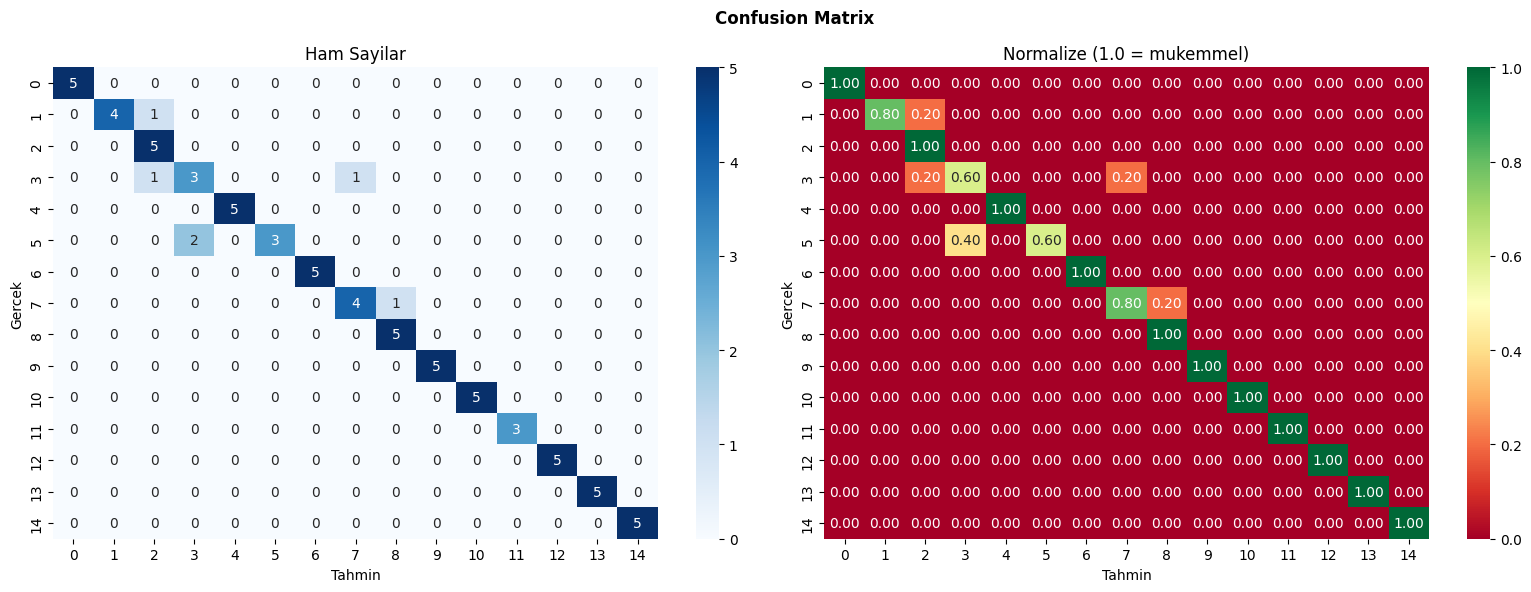

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(y_test, y_pred_test)
n = 15
cm_kucuk = cm[:n, :n]
cm_norm = cm_kucuk / (cm_kucuk.sum(axis=1, keepdims=True) + 1e-6)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Confusion Matrix", fontweight='bold')

sns.heatmap(cm_kucuk, ax=ax1, cmap='Blues', annot=True, fmt='d',
            xticklabels=range(n), yticklabels=range(n))
ax1.set_title("Ham Sayilar")
ax1.set_xlabel("Tahmin"); ax1.set_ylabel("Gercek")

sns.heatmap(cm_norm, ax=ax2, cmap='RdYlGn', annot=True, fmt='.2f',
            xticklabels=range(n), yticklabels=range(n), vmin=0, vmax=1)
ax2.set_title("Normalize (1.0 = mukemmel)")
ax2.set_xlabel("Tahmin"); ax2.set_ylabel("Gercek")

plt.tight_layout()
plt.show()

Toplam yanlis: 16 / 215


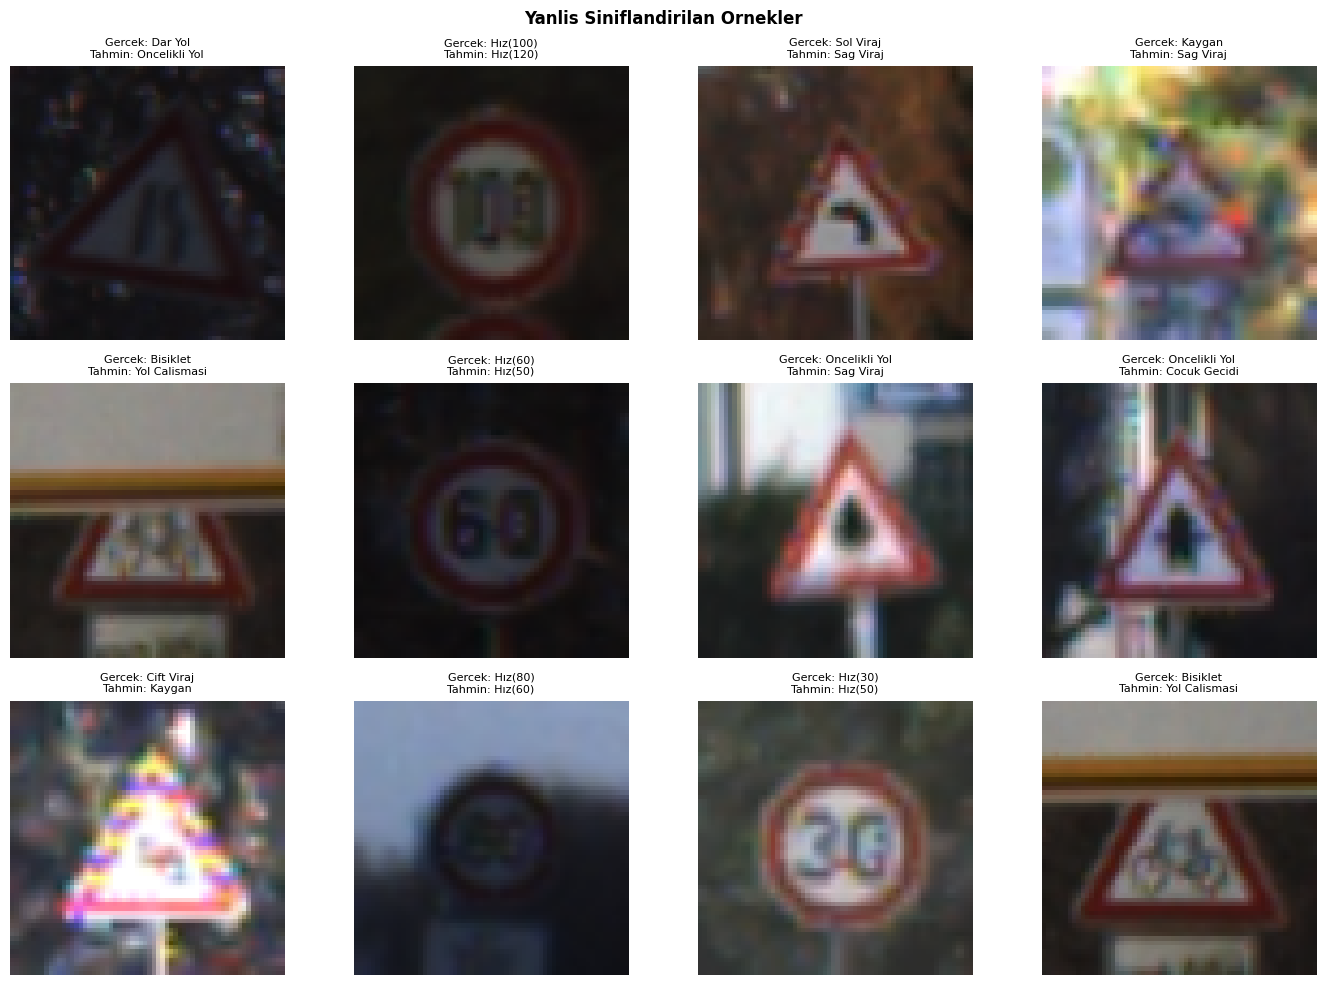

In [ ]:
yanlis = np.where(y_test != y_pred_test)[0]
print(f"Toplam yanlis: {len(yanlis)} / {len(y_test)}")

fig, axs = plt.subplots(3, 4, figsize=(14, 10))
fig.suptitle("Yanlis Siniflandirilan Ornekler", fontweight='bold')
axs = axs.flatten()

CLASS_NAMES = {
    0:"Hız(20)", 1:"Hız(30)", 2:"Hız(50)", 3:"Hız(60)", 4:"Hız(70)",
    5:"Hız(80)", 6:"Hız Sonu(80)", 7:"Hız(100)", 8:"Hız(120)",
    9:"Gecis Yasak", 10:"3.5t Yasak", 11:"Oncelikli Yol",
    12:"Oncelik Ver", 13:"DUR", 14:"Girilmez", 15:"Tum Arac Yasak",
    16:"3.5t Yasak2", 17:"Girilmez2", 18:"Genel Uyari",
    19:"Sol Viraj", 20:"Sag Viraj", 21:"Cift Viraj",
    22:"Engebeli", 23:"Kaygan", 24:"Dar Yol", 25:"Yol Calismasi",
    26:"Trafik Isigi", 27:"Yaya Gecidi", 28:"Cocuk Gecidi",
    29:"Bisiklet", 30:"Buzlanma", 31:"Hayvan Gecidi",
    32:"Yasak Sonu", 33:"saga Don", 34:"Sola Don",
    35:"Duz Git", 36:"Duz/saga", 37:"Duz/Sola",
    38:"Sagdan Gec", 39:"Soldan Gec", 40:"Doner",
    41:"Gecis Yasak Sonu", 42:"3.5t Yasak Sonu"
}

for i, idx in enumerate(yanlis[:12]):
    axs[i].imshow(cv2.cvtColor(X_test[idx], cv2.COLOR_BGR2RGB))
    gercek = CLASS_NAMES.get(y_test[idx], str(y_test[idx]))
    tahmin = CLASS_NAMES.get(y_pred_test[idx], str(y_pred_test[idx]))
    axs[i].set_title(f"Gercek: {gercek}\nTahmin: {tahmin}", fontsize=8)
    for s in axs[i].spines.values():
        s.set_edgecolor('red')
        s.set_linewidth(2.5)
    axs[i].axis('off')

for i in range(len(yanlis[:12]), 12):
    axs[i].axis('off')

plt.tight_layout()
plt.show()

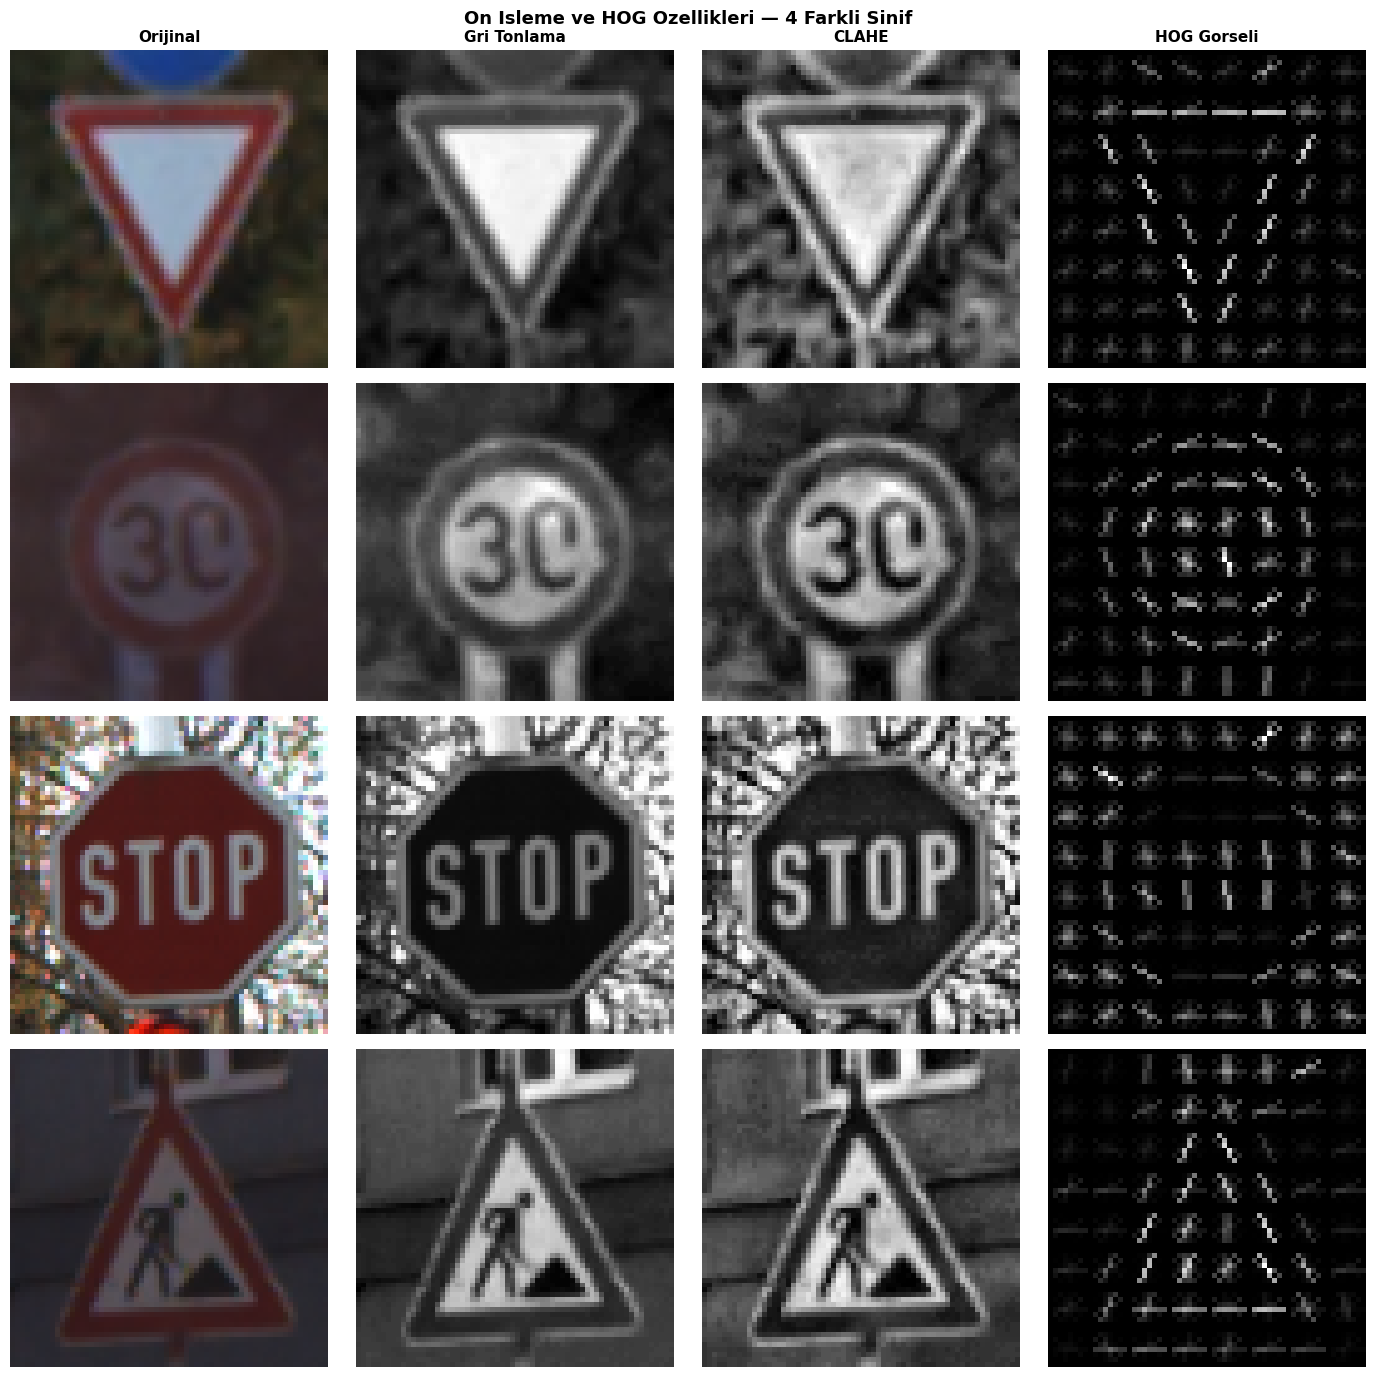

In [ ]:
from skimage.feature import hog
from skimage import exposure

fig, axs = plt.subplots(4, 4, figsize=(14, 14))
fig.suptitle("On Isleme ve HOG Ozellikleri — 4 Farkli Sinif", fontweight='bold', fontsize=13)

siniflar = [13, 1, 14, 25]  # DUR, Hız30, Girilmez, Yol Çalışması
basliklar = ['Orijinal', 'Gri Tonlama', 'CLAHE', 'HOG Gorseli']

for satir, sinif_id in enumerate(siniflar):
    idx = np.where(y_test == sinif_id)[0][0]
    goruntu = X_test[idx]

    # Sütun 1: Orijinal
    axs[satir, 0].imshow(cv2.cvtColor(goruntu, cv2.COLOR_BGR2RGB))
    axs[satir, 0].set_ylabel(CLASS_NAMES[sinif_id], fontsize=9, rotation=0,
                              labelpad=70, va='center')

    # Sütun 2: Gri
    gri = cv2.cvtColor(goruntu, cv2.COLOR_BGR2GRAY)
    axs[satir, 1].imshow(gri, cmap='gray')

    # Sütun 3: CLAHE
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    esit = clahe.apply(gri)
    axs[satir, 2].imshow(esit, cmap='gray')

    # Sütun 4: HOG görseli
    norm = esit.astype(np.float32) / 255.0
    _, hog_img = hog(norm, orientations=9, pixels_per_cell=(8, 8),
                     cells_per_block=(2, 2), block_norm='L2-Hys',
                     visualize=True, feature_vector=True)
    hog_img = exposure.rescale_intensity(hog_img, in_range=(0, 10))
    axs[satir, 3].imshow(hog_img, cmap='gray')

    for ax in axs[satir]:
        ax.axis('off')

for col, baslik in enumerate(basliklar):
    axs[0, col].set_title(baslik, fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()